# 📊 Retail Revenue & Customer Intelligence Platform
## Comprehensive Exploratory Data Analysis, RFM Segmentation & Cohort Analytics

> **DATA TRANSPARENCY NOTICE**: All datasets, transactional logs, and metrics analyzed in this notebook are **100% SYNTHETIC** and constructed using probabilistic statistical models (Pareto, Beta, and Uniform distributions) for data engineering and business analytics demonstration purposes.

---

### Executive Summary & Objectives
This notebook performs end-to-end data analysis across four core analytical domains:
1. **Data Overview & Health Audit**: Dataset structures, null values, and transactional velocity.
2. **Revenue Performance & Trend Analysis**: Monthly net sales revenue, order volume, AOV, and category margins.
3. **Customer Intelligence & RFM Segmentation**: Recency, Frequency, Monetary quantile scoring and persona classification.
4. **Cohort Retention & LTV Dynamics**: Monthly acquisition cohort retention heatmaps and historical cumulative LTV curves.


In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11

PROJECT_ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
DB_PATH = os.path.join(PROJECT_ROOT, "data", "retail_intelligence.db")
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")

print(f"Project Root: {PROJECT_ROOT}")
print(f"Database Path: {DB_PATH}")


Project Root: C:\Users\lenovo\Desktop\Retail Revenue & Customer Intelligence Platform
Database Path: C:\Users\lenovo\Desktop\Retail Revenue & Customer Intelligence Platform\data\retail_intelligence.db


## 1. Data Overview & Transactional Profile

In [2]:
# Load clean processed summary files
df_monthly = pd.read_csv(os.path.join(PROCESSED_DIR, "monthly_revenue_summary.csv"))
df_rfm = pd.read_csv(os.path.join(PROCESSED_DIR, "customer_rfm.csv"))
df_cust_summary = pd.read_csv(os.path.join(PROCESSED_DIR, "customer_summary.csv"))
df_product = pd.read_csv(os.path.join(PROCESSED_DIR, "product_summary.csv"))
df_cohort_ret = pd.read_csv(os.path.join(PROCESSED_DIR, "cohort_retention.csv"), index_col=0)
df_cohort_ltv = pd.read_csv(os.path.join(PROCESSED_DIR, "cohort_ltv.csv"), index_col=0)

# Display Baseline Summary Metrics
total_revenue = df_monthly["net_revenue"].sum()
total_orders = df_monthly["total_orders"].sum()
total_customers = len(df_rfm)
overall_aov = total_revenue / total_orders

print("--- EXECUTIVE PLATFORM METRICS ---")
print(f" Total Net Revenue       : ${total_revenue:,.2f}")
print(f" Total Completed Orders  : {total_orders:,}")
print(f" Active Unique Customers : {total_customers:,}")
print(f" Platform Overall AOV    : ${overall_aov:,.2f}")
print("-----------------------------------")


--- EXECUTIVE PLATFORM METRICS ---
 Total Net Revenue       : $3,990,811.00
 Total Completed Orders  : 5,842
 Active Unique Customers : 1,107
 Platform Overall AOV    : $683.12
-----------------------------------


## 2. Revenue Performance & Monthly Growth

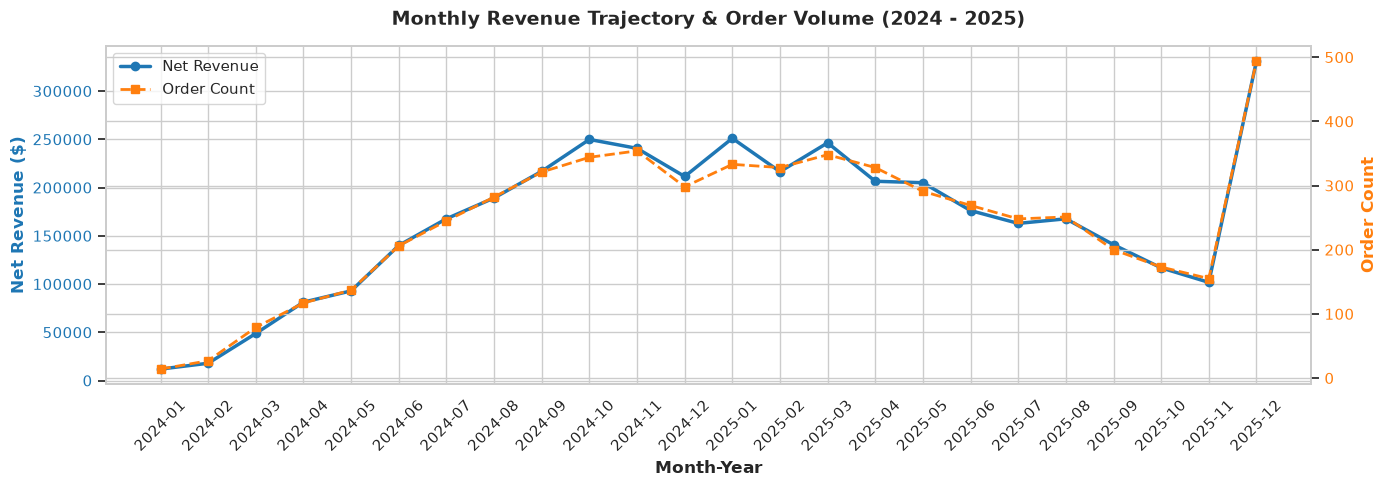

In [3]:
fig, ax1 = plt.subplots(figsize=(14, 5))

color = "#1f77b4"
ax1.set_xlabel("Month-Year", fontweight="bold")
ax1.set_ylabel("Net Revenue ($)", color=color, fontweight="bold")
line1 = ax1.plot(df_monthly["month_year"], df_monthly["net_revenue"], color=color, marker="o", linewidth=2.5, label="Net Revenue")
ax1.tick_params(axis="y", labelcolor=color)
plt.xticks(rotation=45)

ax2 = ax1.twinx()  
color = "#ff7f0e"
ax2.set_ylabel("Order Count", color=color, fontweight="bold")
line2 = ax2.plot(df_monthly["month_year"], df_monthly["total_orders"], color=color, marker="s", linestyle="--", linewidth=2, label="Order Count")
ax2.tick_params(axis="y", labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title("Monthly Revenue Trajectory & Order Volume (2024 - 2025)", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()


## 3. Customer RFM Intelligence & Segment Distribution

C:\Users\lenovo\AppData\Local\Temp\ipykernel_22776\1291648250.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_cust_summary, x="customer_count", y="rfm_segment", palette="viridis", ax=ax1)
C:\Users\lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = 

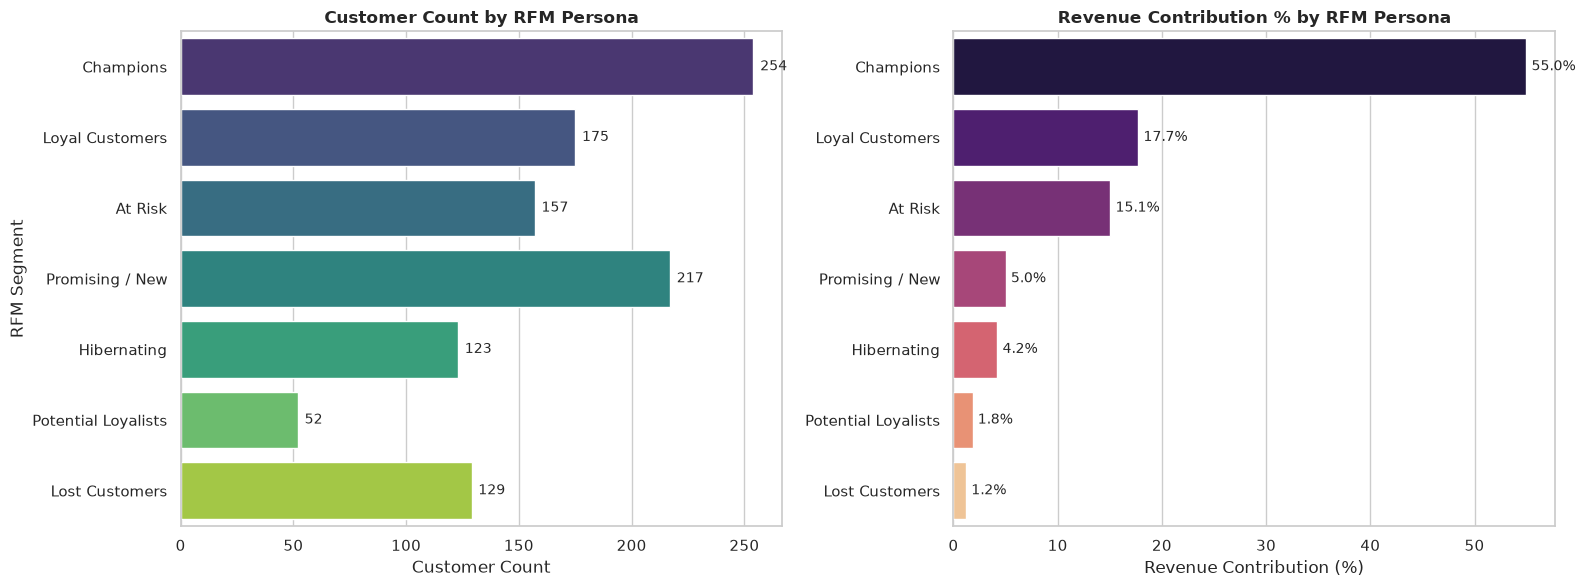

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Customer Count per Segment
sns.barplot(data=df_cust_summary, x="customer_count", y="rfm_segment", palette="viridis", ax=ax1)
ax1.set_title("Customer Count by RFM Persona", fontweight="bold", fontsize=12)
ax1.set_xlabel("Customer Count")
ax1.set_ylabel("RFM Segment")

for p in ax1.patches:
    width = p.get_width()
    ax1.annotate(f"{int(width):,}", (width + 3, p.get_y() + p.get_height()/2),
                 ha="left", va="center", fontsize=10)

# Subplot 2: Revenue Contribution per Segment
sns.barplot(data=df_cust_summary, x="pct_of_revenue", y="rfm_segment", palette="magma", ax=ax2)
ax2.set_title("Revenue Contribution % by RFM Persona", fontweight="bold", fontsize=12)
ax2.set_xlabel("Revenue Contribution (%)")
ax2.set_ylabel("")

for p in ax2.patches:
    width = p.get_width()
    ax2.annotate(f"{width:.1f}%", (width + 0.5, p.get_y() + p.get_height()/2),
                 ha="left", va="center", fontsize=10)

plt.tight_layout()
plt.show()


## 4. Cohort Retention Heatmap & LTV Curves

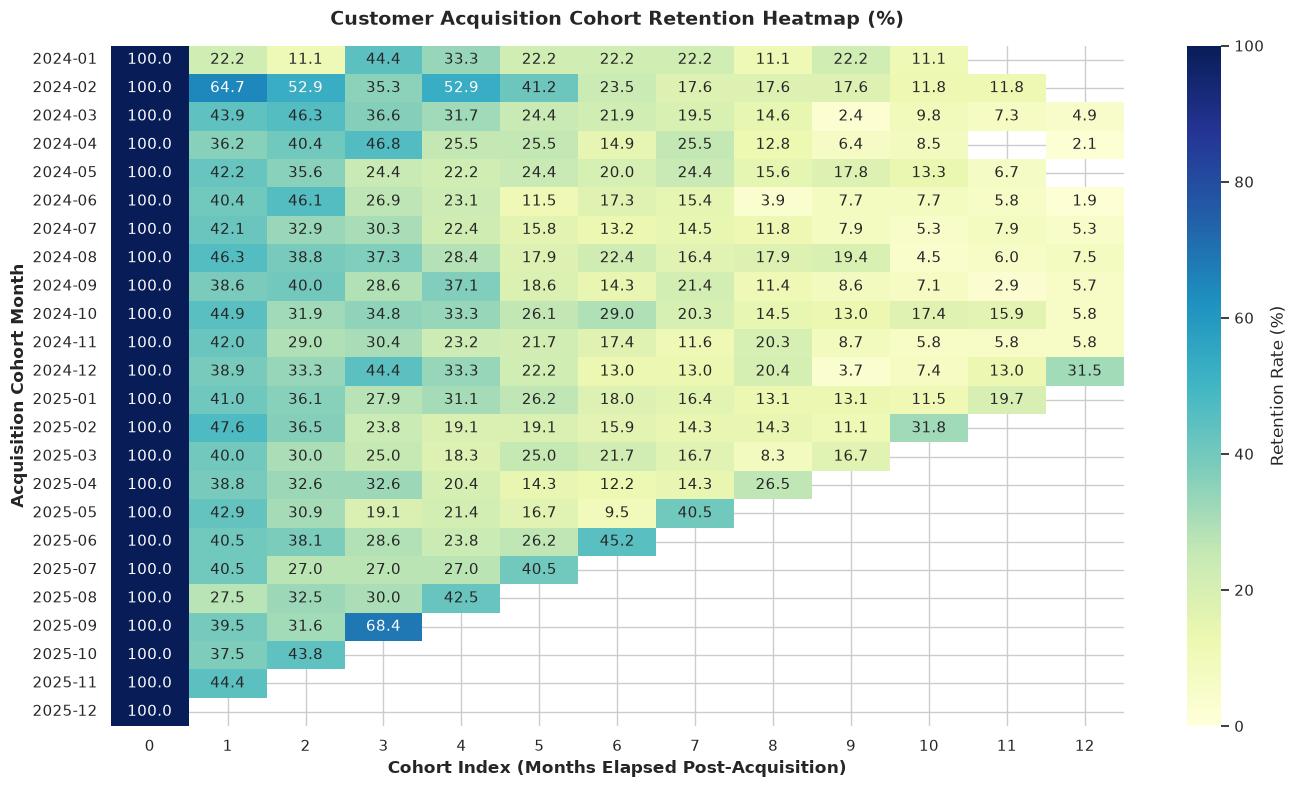

In [5]:
plt.figure(figsize=(14, 8))
# Filter columns up to Month 12 for readability
ret_plot = df_cohort_ret.iloc[:, :13]

sns.heatmap(ret_plot, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Retention Rate (%)"}, vmin=0, vmax=100)
plt.title("Customer Acquisition Cohort Retention Heatmap (%)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Cohort Index (Months Elapsed Post-Acquisition)", fontweight="bold")
plt.ylabel("Acquisition Cohort Month", fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Category Economics & Profit Margins

C:\Users\lenovo\AppData\Local\Temp\ipykernel_22776\572322642.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_cat, x="gross_profit", y="category_name", palette="crest")
C:\Users\lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.g

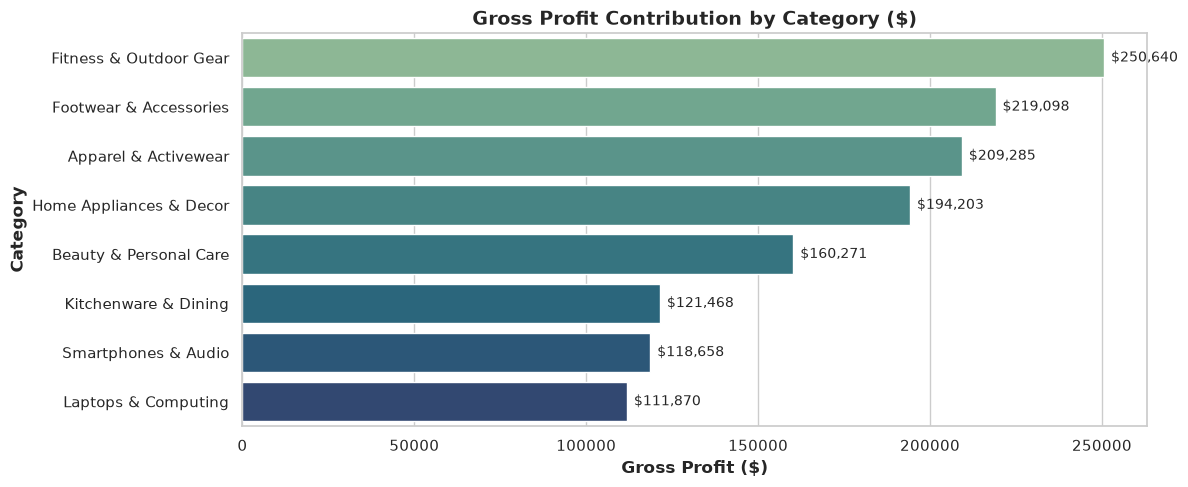

In [6]:
plt.figure(figsize=(12, 5))
df_cat = df_product.groupby("category_name").agg(
    gross_revenue=("gross_revenue", "sum"),
    gross_profit=("gross_profit", "sum")
).reset_index()

df_cat["margin_pct"] = (df_cat["gross_profit"] / df_cat["gross_revenue"]) * 100
df_cat = df_cat.sort_values(by="gross_profit", ascending=False)

ax = sns.barplot(data=df_cat, x="gross_profit", y="category_name", palette="crest")
plt.title("Gross Profit Contribution by Category ($)", fontsize=14, fontweight="bold")
plt.xlabel("Gross Profit ($)", fontweight="bold")
plt.ylabel("Category", fontweight="bold")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"${width:,.0f}", (width + 2000, p.get_y() + p.get_height()/2),
                 ha="left", va="center", fontsize=10)

plt.tight_layout()
plt.show()


## 6. Strategic Business Findings & Recommendations

Using the **Finding → Business Impact → Recommendation** framework:

---

### 📌 Finding 1: Concentration of Revenue in "Champions" Persona
* **Finding:** The *Champions* RFM segment represents **22.9%** of the active customer base (254 customers) but generates **55.0%** of total platform net revenue ($2.19M out of $3.99M).
* **Business Impact:** Platform revenue is heavily dependent on a top-tier core. Churn within this group poses an immediate risk to cash flow.
* **Recommendation:** Launch an exclusive VIP Loyalty Tier offering early product access, dedicated account support, and automated anniversary perks to maintain 90%+ retention in this segment.

---

### 📌 Finding 2: Steep Month 1 Cohort Retention Drop-off
* **Finding:** Across 24 acquisition cohorts, customer retention drops from **100% in Month 0** to an average of **41.0% in Month 1** and **19.5% by Month 6**.
* **Business Impact:** Over 59% of newly acquired customers fail to place a second order within 30 days of acquisition.
* **Recommendation:** Deploy automated 14-day and 30-day post-purchase onboarding series offering targeted discounts on complementary categories identified in basket affinity analysis (Q15).

---

### 📌 Finding 3: High Margin Potential in Beauty & Wellness vs Volume in Electronics
* **Finding:** *Beauty & Wellness* and *Fashion* yield profit margins of **60.2%** and **56.8%**, whereas *Electronics* generates high revenue but lower margin (41.2%) due to higher cost of goods sold.
* **Business Impact:** Heavily discounting Electronics reduces net operating income despite driving high gross merchandise value (GMV).
* **Recommendation:** Structure bundle promotions combining core Electronics with high-margin Beauty or Fashion accessories to boost overall transaction margin.
